<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session04_overfitting_and_regularization_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۴: رگرسیون چندجمله‌ای، بیش‌برازش و منظم‌سازی

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session04_overfitting_and_regularization.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, ElasticNetCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, validation_curve, learning_curve
from sklearn.metrics import root_mean_squared_error
import seaborn as sns

sns.set_theme(style="whitegrid")

rng = np.random.default_rng(42)
X = 6 * rng.random((60, 1)) - 3
y = 0.5 * X[:, 0] ** 2 + X[:, 0] + 2 + rng.normal(0, 1, 60)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

منحنی اعتبارسنجی بخش ۴ را با `Ridge(alpha=1)` به‌جای `LinearRegression` دوباره رسم کنید. شکل منحنی برای درجه‌های بالا چطور تغییر می‌کند؟

</div>

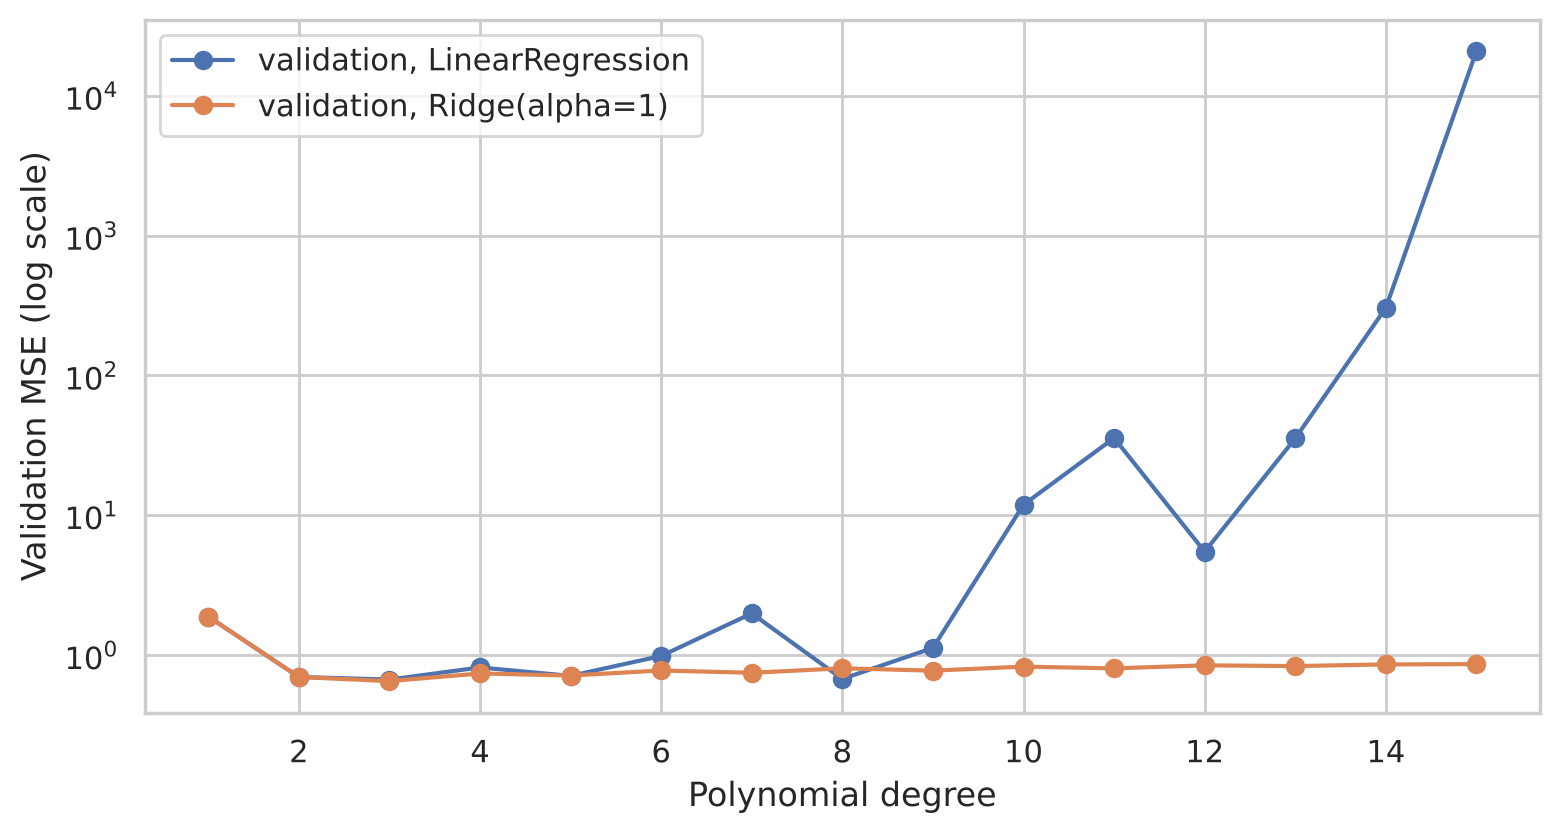

In [2]:
degrees = np.arange(1, 16)
fig, ax = plt.subplots(figsize=(9, 4.5))
for reg, name in [(LinearRegression(), "LinearRegression"), (Ridge(alpha=1), "Ridge(alpha=1)")]:
    model = make_pipeline(PolynomialFeatures(include_bias=False), StandardScaler(), reg)
    _, val = validation_curve(model, X_train, y_train, param_name="polynomialfeatures__degree",
                              param_range=degrees, cv=5, scoring="neg_mean_squared_error")
    ax.plot(degrees, -val.mean(axis=1), "o-", label=f"validation, {name}")
ax.set_yscale("log")
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("Validation MSE (log scale)")
ax.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

بدون منظم‌سازی، خطای اعتبارسنجی برای درجه‌های بالا به‌شدت بالا می‌رود. با Ridge، منحنی برای درجه‌های بالا **تقریباً صاف** می‌ماند: منظم‌سازی جلوی ضرایب بزرگ را می‌گیرد، پس حتی مدل درجهٔ ۱۵ هم نمی‌تواند پیچ‌وتاب‌های شدید بسازد. منظم‌سازی، مدل را نسبت به انتخاب بیش از حد پیچیده **مقاوم** می‌کند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

منحنی یادگیری را برای مدل درجهٔ ۲ رسم کنید و با دو منحنی بخش ۵ مقایسه کنید.

</div>

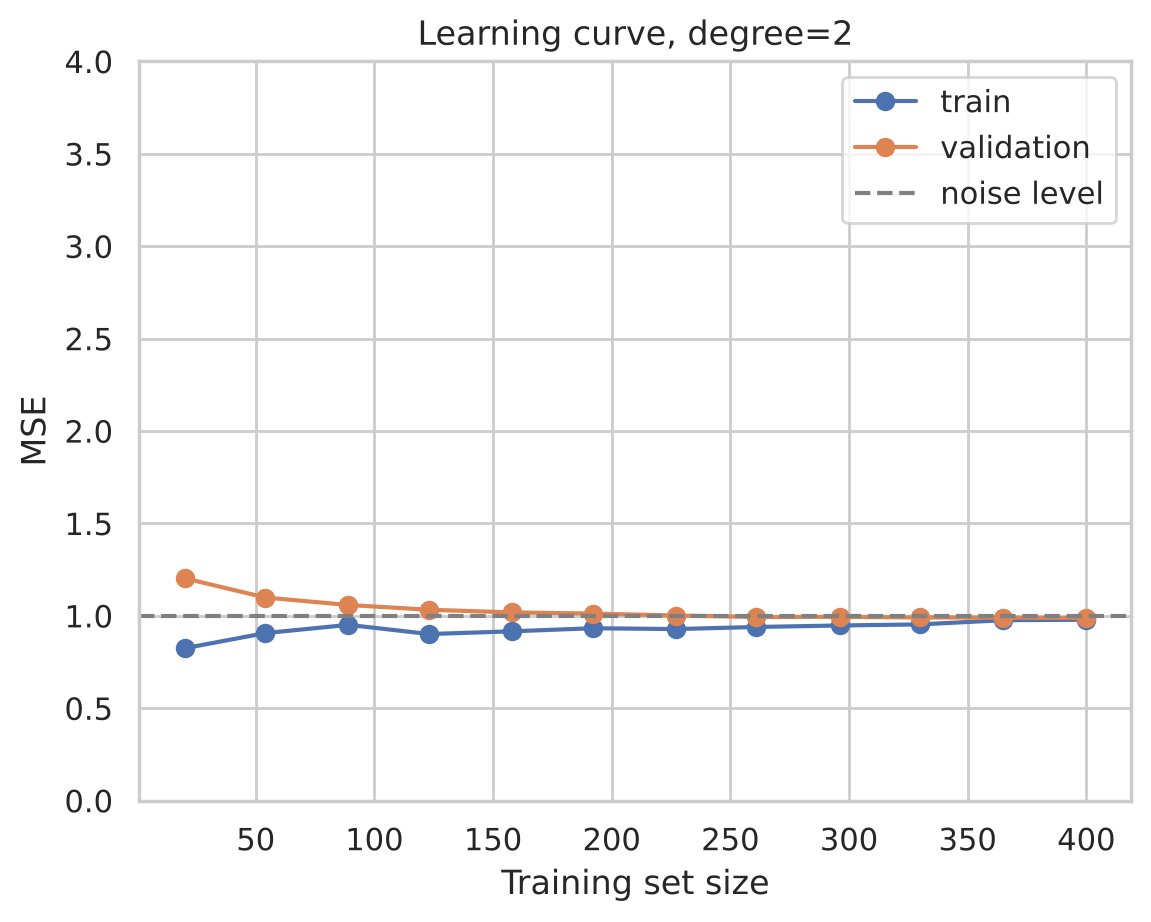

In [3]:
def true_function(x):
    return 0.5 * x ** 2 + x + 2

X_big = 6 * rng.random((500, 1)) - 3
y_big = true_function(X_big[:, 0]) + rng.normal(0, 1, 500)

model = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression())
sizes, tr, va = learning_curve(model, X_big, y_big, cv=5, scoring="neg_mean_squared_error",
                               train_sizes=np.linspace(0.05, 1.0, 12), shuffle=True, random_state=0)
plt.plot(sizes, -tr.mean(axis=1), "o-", label="train")
plt.plot(sizes, -va.mean(axis=1), "o-", label="validation")
plt.axhline(1.0, color="gray", linestyle="--", label="noise level")
plt.ylim(0, 4)
plt.xlabel("Training set size")
plt.ylabel("MSE")
plt.title("Learning curve, degree=2")
plt.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

هر دو منحنی خیلی زود به **سطح نویز** (MSE حدود ۱) می‌رسند و تقریباً روی هم قرار می‌گیرند. این شکل یک مدل **مناسب** است: نه مثل درجهٔ ۱ در سطح بالا گیر کرده (بایاس زیاد)، نه مثل درجهٔ ۱۲ فاصلهٔ زیادی بین آموزش و اعتبارسنجی دارد (واریانس زیاد). از اینجا به بعد، نه دادهٔ بیشتر و نه مدل پیچیده‌تر کمک چندانی نمی‌کند، چون باقی‌ماندهٔ خطا نویز غیرقابل‌کاهش است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

روی دادهٔ مسکن جلسهٔ ۳، Pipeline با `PolynomialFeatures(degree=2)` و `RidgeCV` بسازید. RMSE آزمون نسبت به رگرسیون خطی ساده بهتر می‌شود؟

</div>

In [4]:
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
housing = pd.read_csv(DATA_URL + "housing.csv")
Xh = housing.drop(columns="median_house_value")
yh = housing["median_house_value"]
Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, yh, test_size=0.2, random_state=42)
numeric = Xh.select_dtypes("number").columns.tolist()

def housing_model(degree, regressor):
    num_steps = [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    if degree > 1:
        num_steps += [("poly", PolynomialFeatures(degree, include_bias=False)), ("scale2", StandardScaler())]
    prep = ColumnTransformer([("num", Pipeline(num_steps), numeric),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"])])
    return Pipeline([("prep", prep), ("model", regressor)])

linear = housing_model(1, LinearRegression()).fit(Xh_train, yh_train)
poly_ridge = housing_model(2, RidgeCV(alphas=np.logspace(-2, 3, 30))).fit(Xh_train, yh_train)
print(f"Linear regression RMSE:            {root_mean_squared_error(yh_test, linear.predict(Xh_test)):,.0f}")
print(f"Polynomial (degree 2) + RidgeCV:   {root_mean_squared_error(yh_test, poly_ridge.predict(Xh_test)):,.0f}")
print("Chosen alpha:", round(poly_ridge.named_steps["model"].alpha_, 3))

Linear regression RMSE:            70,059
Polynomial (degree 2) + RidgeCV:   65,456
Chosen alpha: 204.336


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

ویژگی‌های درجهٔ دوم (مربع‌ها و حاصل‌ضرب‌های دوبه‌دو) به مدل اجازه می‌دهند رابطه‌های غیرخطی و تعامل ویژگی‌ها را بگیرد و RMSE آزمون بهتر می‌شود. `RidgeCV` با انتخاب خودکار $\alpha$ جلوی بیش‌برازش ناشی از ده‌ها ویژگی جدید را می‌گیرد. در جلسهٔ ۹ می‌بینیم مدل‌های درختی همین رابطه‌های غیرخطی را بدون ساختن دستی ویژگی و با دقت بیشتر یاد می‌گیرند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

`ElasticNetCV` را روی دادهٔ دیابت امتحان کنید و `l1_ratio` بهینه را گزارش کنید.

</div>

In [5]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(diabetes.data, diabetes.target, test_size=0.25,
                                                        random_state=42)
enet = ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0], alphas=np.logspace(-4, 1, 50),
                    cv=5, max_iter=50_000).fit(Xd_train, yd_train)
print("Best l1_ratio:", enet.l1_ratio_)
print("Best alpha:   ", round(enet.alpha_, 5))
print(f"Test RMSE:     {root_mean_squared_error(yd_test, enet.predict(Xd_test)):.2f}")
print("Non-zero coefficients:", int(np.sum(enet.coef_ != 0)), "of", len(enet.coef_))

Best l1_ratio: 0.95
Best alpha:    0.00026
Test RMSE:     53.29
Non-zero coefficients: 10 of 10


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`l1_ratio` بین صفر (Ridge خالص) و یک (Lasso خالص) است و `ElasticNetCV` هم آن و هم $\alpha$ را با اعتبارسنجی متقابل انتخاب می‌کند. خطای آزمون تقریباً همان خطای Ridge و Lasso در نوت‌بوک جلسه است؛ در این داده، نوع منظم‌سازی تفاوت بزرگی ایجاد نمی‌کند. Elastic Net وقتی بیشترین کاربرد را دارد که گروهی از ویژگی‌های **همبسته** داریم: Lasso معمولاً یکی از آن‌ها را به‌طور دلخواه نگه می‌دارد، ولی Elastic Net همه را با هم و با ضرایب کوچک‌تر نگه می‌دارد.

</div>